# 02 — Exploratory analysis: chess clock increments and timeout losses

**Primary candidate design:** Compare a **2-second increment** against **no increment**, separately for 120-, 180-, and 300-second starting clocks (`120+2` vs `120+0`, `180+2` vs `180+0`, and `300+2` vs `300+0`). The outcome is player-level loss on time. This is **descriptive analysis only**; no causal effects are estimated here.

The original any-positive-increment EDA (Sections 1–6) is retained as background, but those pooled comparisons **do not define the primary treatment**. Sections 7–11 focus on exact 0-versus-2-second policies. A `300+5` versus `300+0` analysis is secondary.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (9, 5)

cwd = Path.cwd().resolve()
roots = [cwd, cwd.parent]
root = next((p for p in roots if (p / "data" / "processed" / "increment_player_games.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("Place CSV files in <repo>/data/processed/ and open the notebook from <repo>/notebooks/ or <repo>.")
pg = pd.read_csv(root / "data/processed/increment_player_games.csv", parse_dates=["started_at_utc"])
games = pd.read_csv(root / "data/processed/increment_games.csv", parse_dates=["started_at_utc"])
print(f"Project root: {root}")
print(f"{len(games):,} games | {len(pg):,} player–game rows | {pg.player.nunique():,} players")

Project root: C:\Users\jenny\Projects\lichess-increment-causal-inference
112,440 games | 224,880 player–game rows | 4,826 players


## 1. Establish the analytic cohort and outcome

Use the same population as Notebook 1. The `lost_on_time` variable records a **decisive timeout loss**; a time-forfeit draw is not a loss. Do not remove other game endings: those count as `lost_on_time = 0` for the player in this binary-outcome analysis.

`common_support_base` tells us only whether both treatment groups exist for a given **initial clock duration**. It does *not* establish comparable players or outcomes.

In [2]:
required = ["game_id", "player", "opponent", "player_elo", "opponent_elo", "elo_diff", "initial_seconds", "increment_seconds", "has_increment", "lost_on_time", "common_support_base", "color", "started_at_utc", "time_control"]
assert not pg[required].isna().any().any()
assert set(pg["has_increment"].unique()) <= {0, 1}
assert set(pg["lost_on_time"].unique()) <= {0, 1}
assert pg.groupby("game_id").size().eq(2).all()
assert pg.groupby("game_id")["has_increment"].nunique().eq(1).all()
assert pg["lost_on_time"].sum() == ((games.termination == "Time forfeit") & games.result.isin(["1-0", "0-1"])).sum()

pg["treatment"] = pg["has_increment"].map({0: "No increment", 1: "Increment"})
games["treatment"] = games["has_increment"].map({0: "No increment", 1: "Increment"})
summary = pg.groupby("treatment").agg(
    player_games=("game_id", "size"), unique_games=("game_id", "nunique"),
    players=("player", "nunique"), timeout_losses=("lost_on_time", "sum"),
    timeout_rate=("lost_on_time", "mean"), avg_player_elo=("player_elo", "mean"),
    median_initial_seconds=("initial_seconds", "median")
)
display(summary.round(3))

,player_games,unique_games,players,timeout_losses,timeout_rate,avg_player_elo,median_initial_seconds
treatment,,,,,,,
Increment,115734,57867,3942,11727,0.101,1560.565,300.0
No increment,109146,54573,3599,20532,0.188,1640.136,180.0


## 2. Treatment policy and time-control mix

Positive increments may vary from small to very large. The pooled treatment compares **a mixture of policies** with zero increment, not a single `300+5` intervention. We will inspect the most popular exact controls and the distribution of increment sizes.

,time_control,initial_seconds,increment_seconds,has_increment,games
243,60+0,60,0,0,14523
141,300+0,300,0,0,10172
94,180+0,180,0,0,8243
22,120+0,120,0,0,5950
166,300+8,300,8,1,5478
163,300+5,300,5,1,4307
125,240+0,240,0,0,3850
103,180+3,180,3,1,3034
153,300+2,300,2,1,2991
244,60+1,60,1,1,2966


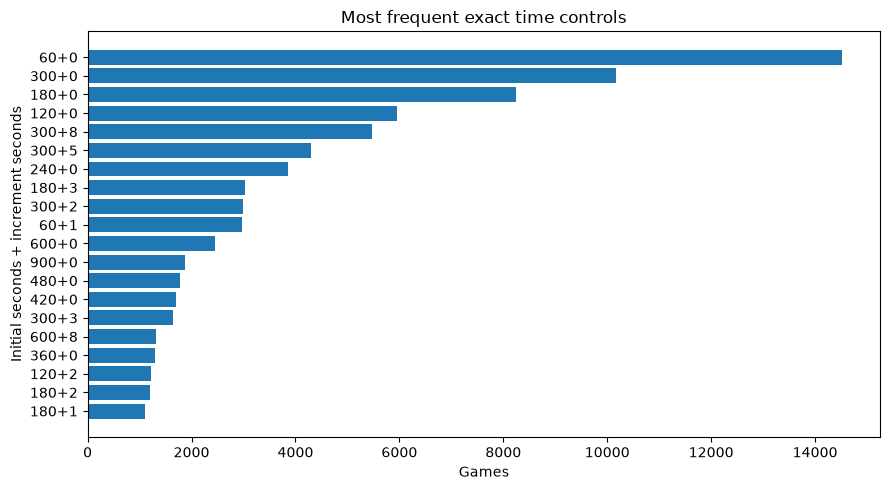

Positive increment seconds (game-level quantiles):


,increment_seconds
count,57867.000000
mean,5.830145
std,4.725488
min,1.000000
10%,1.000000
25%,2.000000
50%,5.000000
75%,8.000000
90%,10.000000
95%,15.000000


In [3]:
top_controls = games.groupby(["time_control", "initial_seconds", "increment_seconds", "has_increment"]).size().rename("games").reset_index().sort_values("games", ascending=False).head(20)
display(top_controls)
fig, ax = plt.subplots()
top = top_controls.sort_values("games")
ax.barh(top["time_control"], top["games"])
ax.set(title="Most frequent exact time controls", xlabel="Games", ylabel="Initial seconds + increment seconds")
plt.tight_layout(); plt.show()
print("Positive increment seconds (game-level quantiles):")
display(games.loc[games.has_increment.eq(1), "increment_seconds"].describe(percentiles=[.1,.25,.5,.75,.9,.95]).to_frame("increment_seconds"))

## 3. Crude treatment–outcome association

These are **per-player probabilities**, not percentages of games. A decisive time forfeit produces one `lost_on_time=1` and one `lost_on_time=0`; a time-forfeit draw produces two zeros. The pooled difference is unadjusted.

,mean,size,sum
has_increment,,,
No increment,0.188115,109146,20532
Increment,0.101327,115734,11727


Crude treated minus untreated difference: -8.68 percentage points (NOT causal)


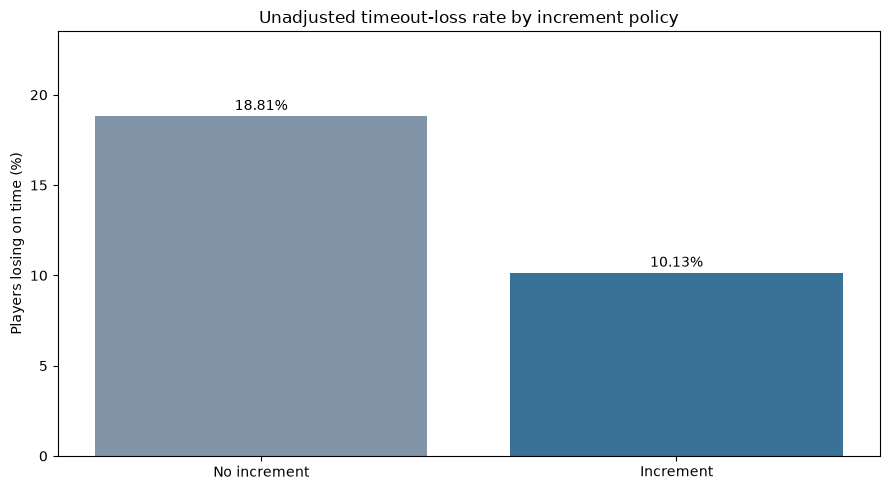

In [4]:
rates = pg.groupby("has_increment")["lost_on_time"].agg(["mean", "size", "sum"])
display(rates.rename(index={0: "No increment", 1: "Increment"}))
crude_pp = 100 * (rates.loc[1, "mean"] - rates.loc[0, "mean"])
print(f"Crude treated minus untreated difference: {crude_pp:.2f} percentage points (NOT causal)")
fig, ax = plt.subplots()
ax.bar(["No increment", "Increment"], 100*rates["mean"], color=["#8194A8", "#3A7197"])
ax.set(ylabel="Players losing on time (%)", title="Unadjusted timeout-loss rate by increment policy")
ax.set_ylim(0, max(100*rates["mean"])*1.25)
for i, v in enumerate(100*rates["mean"]):ax.text(i, v+0.35, f"{v:.2f}%", ha="center")
plt.tight_layout();plt.show()

## 4. Compare starting clocks and baseline ratings

Initial clock is a design variable that should be **held fixed** when possible. Player rating and opponent rating are pre-game characteristics potentially related to time-control selection and timeout risk. `elo_diff` is a useful summary but is mathematically determined by the two ratings; don't use all three uncritically in the same regression.

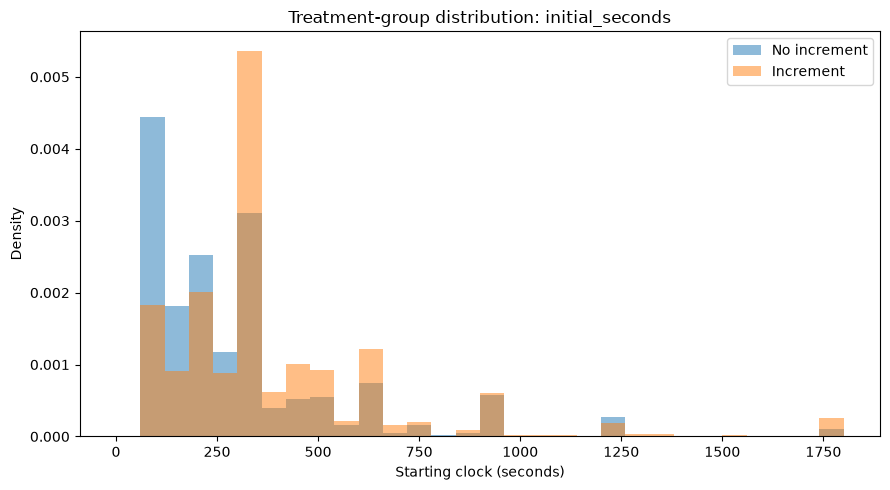

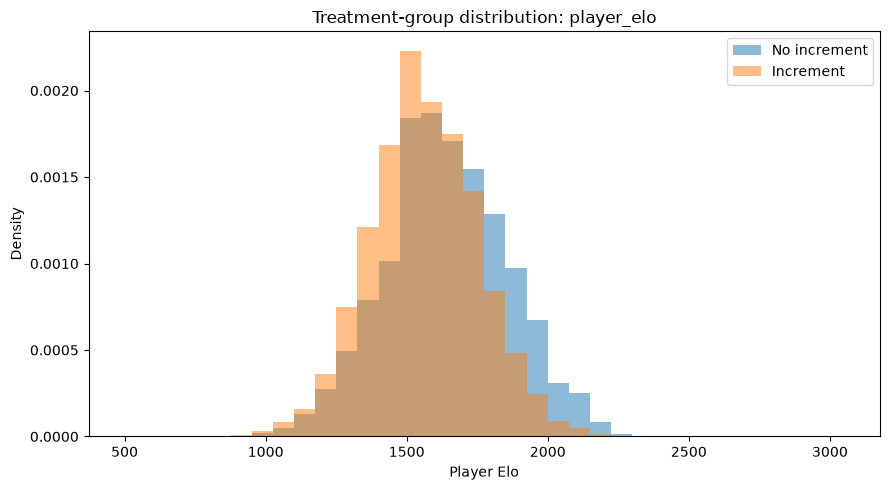

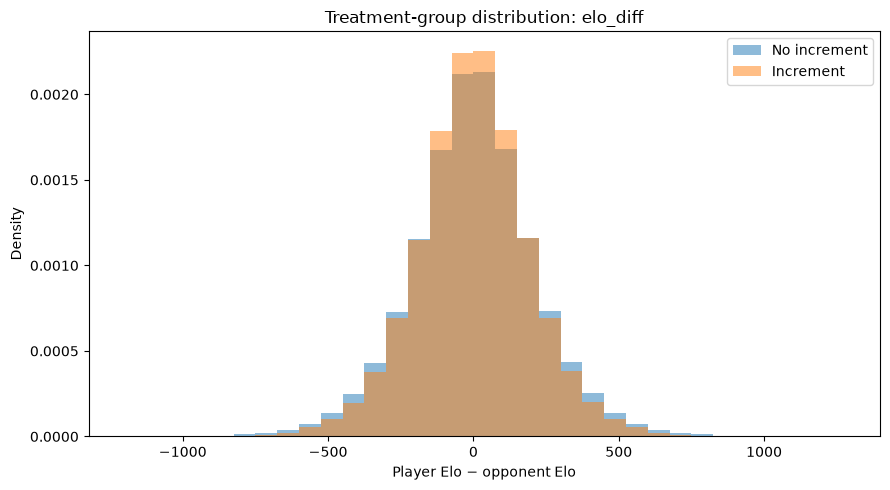

Starting-clock plots cap at 1,800 seconds for readability; full data remains included elsewhere.


In [5]:
for variable, xlabel in [("initial_seconds", "Starting clock (seconds)"), ("player_elo", "Player Elo"), ("elo_diff", "Player Elo − opponent Elo")]:
    fig, ax = plt.subplots()
    for t, lab in [(0, "No increment"), (1, "Increment")]:
        values = pg.loc[pg.has_increment.eq(t), variable]
        if variable == "initial_seconds":
            values = values[values.le(1800)]
            bins = np.arange(0, 1860, 60)
        elif variable == "player_elo": bins = np.arange(500, 3100, 75)
        else: bins = np.arange(-1200, 1300, 75)
        ax.hist(values, bins=bins, density=True, alpha=.5, label=lab)
    ax.set(xlabel=xlabel, ylabel="Density", title=f"Treatment-group distribution: {variable}")
    ax.legend(); plt.tight_layout(); plt.show()
print("Starting-clock plots cap at 1,800 seconds for readability; full data remains included elsewhere.")

## 5. Stratify by identical starting-clock duration

Calculate treated and untreated rates *within* initial durations, limiting displayed rows to durations with at least 100 **games per arm**. This removes one obvious source of imbalance from the comparison, but does not address selection within starting-clock groups.

,initial_seconds,player_games_no_inc,player_games_inc,timeout_rate_no_inc,timeout_rate_inc,avg_elo_no_inc,avg_elo_inc,rate_diff_pp,elo_diff_between_arms
4,300,20344.0,37252.0,0.150,0.094,1596.773,1559.788,-5.598,-36.985
2,180,16486.0,13970.0,0.208,0.119,1677.454,1617.489,-8.875,-59.965
0,60,29046.0,12686.0,0.277,0.165,1720.009,1590.308,-11.291,-129.701
9,600,4896.0,8484.0,0.103,0.072,1553.433,1524.676,-3.092,-28.757
6,420,3386.0,6990.0,0.125,0.081,1606.849,1566.295,-4.439,-40.554
7,480,3572.0,6390.0,0.117,0.069,1570.215,1546.454,-4.829,-23.762
1,120,11900.0,6344.0,0.206,0.121,1640.628,1585.204,-8.580,-55.423
3,240,7700.0,6128.0,0.137,0.130,1669.285,1521.743,-0.689,-147.543
5,360,2596.0,4266.0,0.143,0.083,1500.100,1540.900,-6.055,40.800
14,900,3756.0,4170.0,0.075,0.069,1557.035,1499.518,-0.599,-57.517


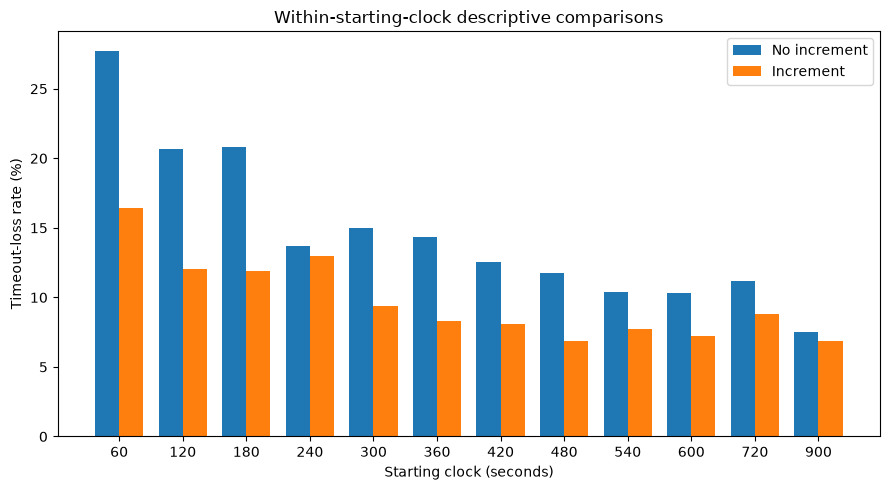

In [6]:
base = pg.groupby(["initial_seconds", "has_increment"]).agg(
    player_games=("game_id", "size"), timeout_rate=("lost_on_time", "mean"),
    avg_elo=("player_elo", "mean"),
).reset_index()
base_pivot = base.pivot(index="initial_seconds", columns="has_increment", values=["player_games", "timeout_rate", "avg_elo"])
base_pivot.columns = [f"{metric}_{'inc' if t else 'no_inc'}" for metric,t in base_pivot.columns]
base_pivot = base_pivot.reset_index().fillna(0)
eligible = base_pivot.query("player_games_inc >= 200 and player_games_no_inc >= 200").copy()
eligible["rate_diff_pp"] = 100 * (eligible["timeout_rate_inc"] - eligible["timeout_rate_no_inc"])
eligible["elo_diff_between_arms"] = eligible["avg_elo_inc"] - eligible["avg_elo_no_inc"]
display(eligible.sort_values("player_games_inc", ascending=False).head(20).round(3))
fig, ax = plt.subplots()
chart = eligible.sort_values("player_games_inc", ascending=False).head(12).sort_values("initial_seconds")
x=np.arange(len(chart)); w=.38
ax.bar(x-w/2, 100*chart.timeout_rate_no_inc, w, label="No increment")
ax.bar(x+w/2, 100*chart.timeout_rate_inc, w, label="Increment")
ax.set_xticks(x, chart.initial_seconds.astype(int).astype(str))
ax.set(xlabel="Starting clock (seconds)",ylabel="Timeout-loss rate (%)",title="Within-starting-clock descriptive comparisons")
ax.legend();plt.tight_layout();plt.show()

## 6. Baseline balance using standardized mean differences (SMDs)

A standardized mean difference is the treated–control difference in means divided by their pooled standard deviation. SMD measures *imbalance*, not a p-value or causal effect. Compute it overall and then within a practical five-minute (`initial_seconds == 300`) cohort.

For the primary analysis, player/opponent Elo and color are measured at or before the game. **Do not adjust for move count, game length, termination, or game result** as explanatory covariates: they occur after treatment or are derived from the outcome.

,variable,SMD_all,SMD_300s
0,player_elo,-0.391,-0.19
1,opponent_elo,-0.391,-0.19
2,elo_diff,0.000,0.00
3,is_white,0.000,0.00
4,initial_seconds,0.334,NaN


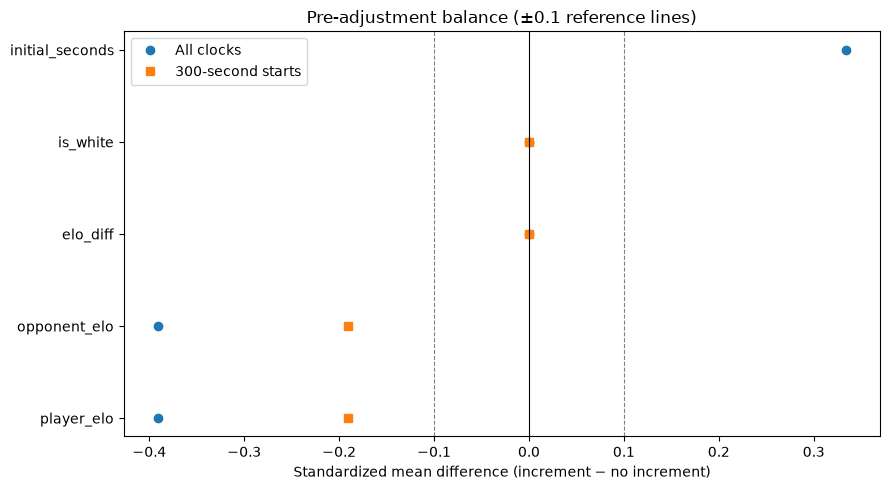

In [7]:
def smd(frame, column):
    a = frame.loc[frame.has_increment.eq(1), column].astype(float)
    b = frame.loc[frame.has_increment.eq(0), column].astype(float)
    v = (a.var(ddof=1)+b.var(ddof=1))/2
    return (a.mean()-b.mean())/np.sqrt(v) if v > 0 else np.nan

pg["is_white"] = pg.color.eq("white").astype(int)
variables = ["player_elo", "opponent_elo", "elo_diff", "is_white", "initial_seconds"]
rows=[]
for v in variables:
    rows.append({"variable":v,"SMD_all":smd(pg,v),"SMD_300s":smd(pg.loc[pg.initial_seconds.eq(300)],v)})
smd_tbl=pd.DataFrame(rows)
display(smd_tbl.round(3))
fig,ax=plt.subplots()
y=np.arange(len(smd_tbl)); ax.plot(smd_tbl.SMD_all,y,"o",label="All clocks");ax.plot(smd_tbl.SMD_300s,y,"s",label="300-second starts")
ax.axvline(0,color="black",lw=.8);ax.axvline(.1,color="gray",ls="--",lw=.8);ax.axvline(-.1,color="gray",ls="--",lw=.8)
ax.set_yticks(y,smd_tbl.variable);ax.set(xlabel="Standardized mean difference (increment − no increment)",title="Pre-adjustment balance (±0.1 reference lines)")
ax.legend();plt.tight_layout();plt.show()

## 7. Primary exact-policy cohort: +2 seconds versus +0

Restrict attention to **120, 180, or 300 seconds** initial time, with **exactly 0 or 2 seconds** increment. Do not treat `300+5` or `300+8` as part of the primary treated group. Compare rates **within starting-clock strata** to avoid compositional artifacts. Rates below are observational, not estimates of causal effects.

Primary sample: 29,762 games; 59,524 player-game observations


,games
policy,
120+0,5950
120+2,1212
180+0,8243
180+2,1194
300+0,10172
300+2,2991


,initial_seconds,increment_seconds,player_games,timeout_losses,timeout_rate,players,mean_player_elo,timeout_rate_pct
0,120,0,11900,2456,0.21,1014,1640.63,20.64
1,120,2,2424,286,0.12,472,1655.90,11.80
2,180,0,16486,3428,0.21,1654,1677.45,20.79
3,180,2,2388,298,0.12,499,1657.98,12.48
4,300,0,20344,3046,0.15,1808,1596.77,14.97
5,300,2,5982,665,0.11,969,1578.70,11.12


increment_seconds,no_increment_rate,two_sec_rate,raw_difference_pp
initial_seconds,,,
120,0.2064,0.1180,-8.8400
180,0.2079,0.1248,-8.3143
300,0.1497,0.1112,-3.8558


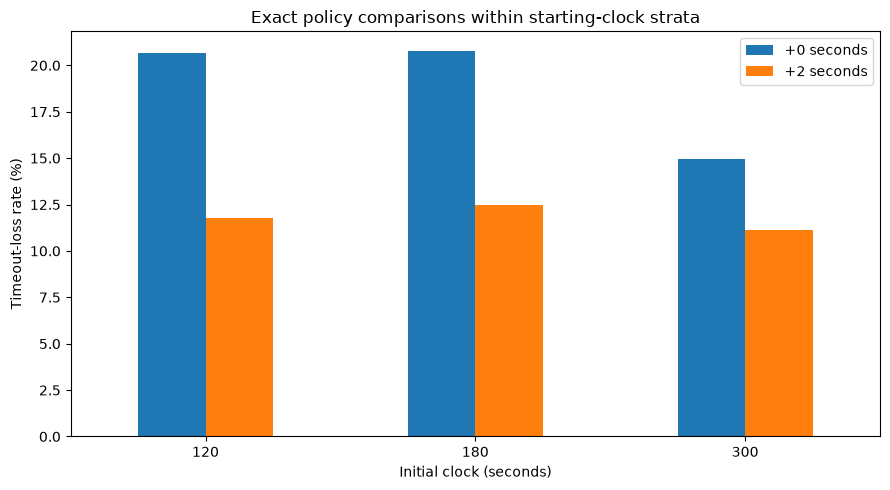

In [8]:
PRIMARY_CLOCKS = [120, 180, 300]
primary_games = games.loc[
    games.initial_seconds.isin(PRIMARY_CLOCKS) & games.increment_seconds.isin([0, 2])
].copy()
primary = pg.loc[
    pg.initial_seconds.isin(PRIMARY_CLOCKS) & pg.increment_seconds.isin([0, 2])
].copy()
assert primary.groupby('game_id').size().eq(2).all()
assert primary.groupby('game_id').has_increment.nunique().eq(1).all()

primary['policy'] = primary.initial_seconds.astype(str) + '+' + primary.increment_seconds.astype(str)
primary_games['policy'] = primary_games.initial_seconds.astype(str) + '+' + primary_games.increment_seconds.astype(str)
print(f'Primary sample: {len(primary_games):,} games; {len(primary):,} player-game observations')
display(primary_games.policy.value_counts().sort_index().rename('games').to_frame())

primary_rates = primary.groupby(['initial_seconds','increment_seconds']).agg(
    player_games=('game_id','size'),
    timeout_losses=('lost_on_time','sum'),
    timeout_rate=('lost_on_time','mean'),
    players=('player','nunique'),
    mean_player_elo=('player_elo','mean')
).reset_index()
display(primary_rates.assign(timeout_rate_pct=lambda x:100*x.timeout_rate).round(2))
rate_wide = primary_rates.pivot(index='initial_seconds',columns='increment_seconds',values='timeout_rate')
rate_wide['raw_difference_pp'] = (rate_wide[2]-rate_wide[0])*100
display(rate_wide.rename(columns={0:'no_increment_rate',2:'two_sec_rate'}).round(4))
ax = (100*rate_wide[[0,2]]).plot(kind='bar',figsize=(9,5),rot=0)
ax.set(xlabel='Initial clock (seconds)', ylabel='Timeout-loss rate (%)', title='Exact policy comparisons within starting-clock strata')
ax.legend(['+0 seconds','+2 seconds']);plt.tight_layout();plt.show()

## 8. Exact-policy within-player overlap and player concentration

Within-player comparisons require players who appear under **both `+0` and `+2` within a given starting-clock stratum**. Report exact switcher counts and the number of observations contributed by those players. Also check whether a few frequent players dominate the primary cohort. Switching is not random assignment.

In [9]:
switch_rows = []
for clock in PRIMARY_CLOCKS:
    sub = primary.loc[primary.initial_seconds.eq(clock)]
    policies_per_player = sub.groupby('player').increment_seconds.nunique()
    switchers = policies_per_player.index[policies_per_player.eq(2)]
    sub_switch = sub.loc[sub.player.isin(switchers)]
    switch_rows.append({
        'initial_seconds':clock,
        'switching_players':len(switchers),
        'switcher_player_games':len(sub_switch),
        'switcher_plus0_rows':int(sub_switch.increment_seconds.eq(0).sum()),
        'switcher_plus2_rows':int(sub_switch.increment_seconds.eq(2).sum()),
    })
switch_table = pd.DataFrame(switch_rows)
display(switch_table)

n_per_player=primary.groupby('player').size().sort_values(ascending=False)
display(n_per_player.describe(percentiles=[.5,.75,.9,.95,.99]).to_frame('player_games'))
print(f'Top 10 players share of primary player-game rows: {n_per_player.head(10).sum()/len(primary):.2%}')

,initial_seconds,switching_players,switcher_player_games,switcher_plus0_rows,switcher_plus2_rows
0,120,312,7691,5607,2084
1,180,389,9543,7668,1875
2,300,756,18425,13371,5054


,player_games
count,2819.000000
mean,21.115289
std,56.645416
min,1.000000
50%,4.000000
75%,15.000000
90%,49.000000
95%,98.100000
99%,246.460000
max,1017.000000


Top 10 players share of primary player-game rows: 10.50%


## 9. Exact-policy covariate balance and descriptive rating heterogeneity

Evaluate **pre-adjustment** balance of player Elo, opponent Elo, rating difference, and color **within each starting clock**, not just in the pooled sample. An absolute SMD near or above 0.1 is a useful warning flag, not a definitive threshold for causal validity. Repeat the descriptive outcome comparison within player rating bands, keeping the three starting-clock strata separate.

initial_seconds,120,180,300
variable,,,
elo_diff,0.000,0.000,0.000
is_white,0.000,0.000,0.000
opponent_elo,0.072,-0.093,-0.094
player_elo,0.072,-0.093,-0.094


,initial_seconds,elo_band,increment_seconds,player_games,timeout_rate,timeout_rate_pct
0,120,"[0.0, 1200.0)",0,149,0.42,41.61
1,120,"[0.0, 1200.0)",2,49,0.31,30.61
2,120,"[1200.0, 1400.0)",0,1247,0.33,33.36
3,120,"[1200.0, 1400.0)",2,166,0.20,19.88
4,120,"[1400.0, 1600.0)",0,4436,0.22,22.11
5,120,"[1400.0, 1600.0)",2,686,0.18,17.64
6,120,"[1600.0, 1800.0)",0,3573,0.19,19.00
7,120,"[1600.0, 1800.0)",2,973,0.08,8.02
8,120,"[1800.0, 2000.0)",0,1459,0.17,16.72
9,120,"[1800.0, 2000.0)",2,440,0.07,7.05


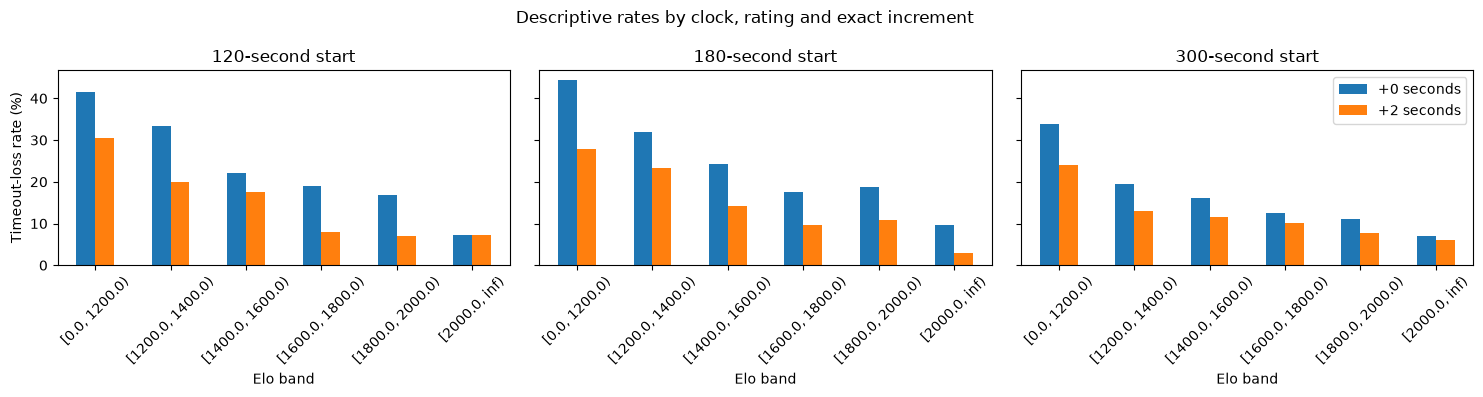

In [10]:
primary['is_white'] = primary.color.eq('white').astype(int)
vars_to_check = ['player_elo','opponent_elo','elo_diff','is_white']
exact_balance = pd.DataFrame([
    {'initial_seconds':clock,'variable':variable,
     'smd_plus2_minus_plus0':smd(primary.loc[primary.initial_seconds.eq(clock)],variable)}
    for clock in PRIMARY_CLOCKS for variable in vars_to_check
])
display(exact_balance.pivot(index='variable',columns='initial_seconds',values='smd_plus2_minus_plus0').round(3))

primary['elo_band'] = pd.cut(primary.player_elo, bins=[0,1200,1400,1600,1800,2000,np.inf], right=False)
by_rating = primary.groupby(['initial_seconds','elo_band','increment_seconds'],observed=True).agg(
    player_games=('game_id','size'),timeout_rate=('lost_on_time','mean')
).reset_index()
display(by_rating.assign(timeout_rate_pct=lambda x:100*x.timeout_rate).round(2))

fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,clock in zip(axes,PRIMARY_CLOCKS):
    sub=by_rating.loc[by_rating.initial_seconds.eq(clock)]
    pivot=sub.pivot(index='elo_band',columns='increment_seconds',values='timeout_rate')
    (100*pivot).plot(kind='bar',ax=ax,rot=45,legend=False)
    ax.set(title=f'{clock}-second start',xlabel='Elo band',ylabel='Timeout-loss rate (%)')
axes[-1].legend(['+0 seconds','+2 seconds'])
plt.suptitle('Descriptive rates by clock, rating and exact increment')
plt.tight_layout();plt.show()

## 10. Secondary policy and saved summaries

As a **secondary/sensitivity comparison**, inspect `300+5` versus `300+0` separately. This asks a different treatment question and must not be combined into the primary +2-second effect. Save aggregate results for the primary design; raw player observations stay local.

In [11]:
secondary = pg.loc[(pg.initial_seconds.eq(300)) & (pg.increment_seconds.isin([0,5]))].copy()
secondary_summary = secondary.groupby('increment_seconds').agg(
    player_games=('game_id','size'),timeout_rate=('lost_on_time','mean'),
    mean_player_elo=('player_elo','mean')
)
display(secondary_summary)
sec_switch=secondary.groupby('player').increment_seconds.nunique().eq(2)
print(f'300+0 / 300+5 switching players: {sec_switch.sum():,}')

results_dir = root/'results'/'tables'
results_dir.mkdir(parents=True,exist_ok=True)
primary_rates.to_csv(results_dir/'eda_exact_plus2_rates.csv',index=False)
switch_table.to_csv(results_dir/'eda_exact_plus2_switchers.csv',index=False)
exact_balance.to_csv(results_dir/'eda_exact_plus2_smd.csv',index=False)
by_rating.to_csv(results_dir/'eda_exact_plus2_rating_bands.csv',index=False)
secondary_summary.to_csv(results_dir/'eda_secondary_300_plus5.csv')
print('Saved aggregated tables to',results_dir)

,player_games,timeout_rate,mean_player_elo
increment_seconds,,,
0,20344,0.149725,1596.773152
5,8614,0.089854,1542.192593


300+0 / 300+5 switching players: 854
Saved aggregated tables to C:\Users\jenny\Projects\lichess-increment-causal-inference\results\tables


## 11. Findings and Design Decision Log

### 11.1 Primary Design

The primary research question is:

**What is the effect of a 2-second per-move increment, compared with no increment, on the probability of losing on time, and how does this effect vary across 120-, 180-, and 300-second starting clocks?**

The primary analysis will compare the following time controls:

- `120+0` versus `120+2`
- `180+0` versus `180+2`
- `300+0` versus `300+2`

The analytic sample consists of **29,762 games**, corresponding to **59,524 player-game observations**.

Restricting the treatment to a fixed 2-second increment creates a more clearly defined intervention than comparing all positive increments against zero increment. Analyzing each starting-clock duration separately also avoids confounding the primary comparison with differences in initial clock duration.

### 11.2 Descriptive Results

Across all three starting-clock durations, games with a 2-second increment exhibited lower observed probabilities of losing on time.

| Starting clock | No increment | +2-second increment | Difference |
|---|---:|---:|---:|
| 120 seconds | 20.64% | 11.80% | −8.84 pp |
| 180 seconds | 20.79% | 12.48% | −8.31 pp |
| 300 seconds | 14.97% | 11.12% | −3.86 pp |

The largest observed difference occurred among games with a 120-second starting clock, while the smallest occurred among games with a 300-second starting clock.

These findings suggest that the relationship between increment availability and timeout losses may vary with starting-clock duration. A 2-second increment could be relatively more consequential in games with less initial time.

However, these differences are descriptive associations rather than causal estimates. Players voluntarily select time controls, and other characteristics may explain some or all of the observed differences.

The broader analysis of any positive increment found an unadjusted timeout-loss rate of 18.81% without increments and 10.13% with increments. This pooled comparison is retained as exploratory context but does not define the primary treatment effect.

### 11.3 Covariate Balance and Treatment Overlap

The dataset contains players who participated in both increment and non-increment games at each starting-clock duration.

| Starting clock | Switching players | Player-game observations from switchers |
|---|---:|---:|
| 120 seconds | 312 | 7,691 |
| 180 seconds | 389 | 9,543 |
| 300 seconds | 756 | 18,425 |

The presence of switching players makes within-player analysis feasible, although players' time-control choices are not randomized.

Standardized mean differences were calculated to assess pre-adjustment covariate balance.

| Covariate | 120 sec | 180 sec | 300 sec |
|---|---:|---:|---:|
| Player Elo | 0.072 | −0.093 | −0.094 |
| Opponent Elo | 0.072 | −0.093 | −0.094 |
| Elo difference | 0.000 | 0.000 | 0.000 |
| Playing White | 0.000 | 0.000 | 0.000 |

The absolute SMDs for player and opponent Elo were below 0.10 across all three starting-clock groups, suggesting relatively small observed rating imbalances.

However, this does not establish that treatment groups are exchangeable. Unmeasured differences in playing style, fatigue, motivation, and time-control preferences may remain.

The zero SMDs for Elo difference and playing White also reflect structural features of the player-game dataset. Each game contributes both players, so color is exactly balanced and the game-level rating differences cancel when aggregated across both perspectives.

The dataset also shows substantial variation in player activity. The median player contributed 4 observations to the primary sample, while the most active contributed 1,017. The 10 most active players accounted for 10.50% of observations.

These findings support considering within-player comparisons and sensitivity analyses for highly active players, while accounting for dependence between observations.

### 11.4 Primary Versus Secondary Analysis

The primary analysis will estimate the association and, subject to identification assumptions, the causal effect of a 2-second increment within the three prespecified starting-clock durations.

As a secondary analysis, `300+0` and `300+5` will be compared to investigate whether a larger increment produces different results among games with identical starting clocks.

For the secondary comparison:

- `300+0` timeout-loss rate: 14.97%
- `300+5` timeout-loss rate: 8.99%
- Unadjusted difference: approximately −5.99 percentage points
- Players observed under both policies: 854

The secondary comparison suggests a stronger negative association for a 5-second increment than for a 2-second increment at the 300-second starting clock.

However, the two increment groups may contain different populations of players. Therefore, their observed differences cannot establish a causal dose-response relationship.

### 11.5 Remaining Threats to Causal Identification

Despite relatively favorable observed balance and treatment overlap, several threats to causal identification remain.

**Self-selection into time controls:** Players choose whether to play with an increment. Their preferences, time-management skills, and playing styles may influence both treatment selection and timeout risk.

**Time-varying confounding:** Fatigue, recent performance, motivation, and time of day may affect both a player's choice of time control and subsequent performance.

**Matchmaking and opponent selection:** Choosing a different time-control queue may change the opponents a player faces. Opponent characteristics could therefore be consequences of treatment selection, complicating their role as adjustment variables.

**Repeated observations:** Players appear in multiple games, and the two player-game observations belonging to the same game are dependent. Conventional independent-observation standard errors would not adequately represent this dependence.

**Concentration of observations:** Highly active players contribute disproportionately to the dataset, potentially influencing estimates and limiting their generalizability to less active players.

Player fixed effects may control for stable, unobserved player characteristics, but cannot remove time-varying confounding.

### 11.6 Next Steps: Causal Design

The next notebook will formalize the study's identification strategy before estimating causal effects.

The main priorities are:

1. Define the intervention precisely, including when time-control selection occurs relative to matchmaking.
2. Specify the target population and causal estimand for each starting-clock duration.
3. Construct a directed acyclic graph (DAG) identifying potential confounders, mediators, and adjustment variables.
4. Determine which covariates can appropriately be adjusted for without introducing post-treatment bias.
5. Evaluate the feasibility of within-player fixed-effects models alongside covariate-adjusted approaches.
6. Develop an uncertainty estimation strategy accounting for repeated players and dependence within games.
7. Establish sensitivity analyses for unmeasured confounding and influential players.

**Conclusion:** The exploratory analysis supports proceeding with the 2-second increment study across 120-, 180-, and 300-second starting clocks. The observed associations are consistently negative, and exact-policy overlap provides opportunities for more rigorous analysis. Nevertheless, causal conclusions will depend on the validity of the assumptions established in the next stage.

**Data source:** January 2013 Lichess standard rated games. All findings in this notebook are descriptive and should not be interpreted as established causal effects.